In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [2]:
import tensorflow as tf

print(tf.test.is_built_with_cuda())
print(tf.config.list_physical_devices('GPU'))
print(tf. __version__)

True
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
2.11.0


In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('../dataset_generation/dataset_130k.csv')

In [4]:
# df = df.iloc[0:10, :] 
df

,algorithm,encrypt
0,vigenere,qlhskblfzvzsbumzsnifkvvhgplmw
1,substitution,bjjnjnsjamfnaasjjudjascnsajfjjgncassca
2,caesar,ignlwpigtetcipcrtrpclwpirpcxicdi
3,vigenere,losqhcfjlvzybugusrrjvyywdipygdglxzygmznyb
4,caesar,mehjxojeruqhurubvehjejxqj
...,...,...
133875,substitution,vecaamqecodhemvdvajcacdhmedhqeccqd
133876,affine,yfbylksinybj
133877,rail_fence,dienglohattyeictnneohtmiilhlehva
133878,affine,ldbbbtjhllbbtvhpbhttpvxbtldbhbhbvhzxzzj


In [5]:
df.algorithm.unique()

array(['vigenere', 'substitution', 'caesar', 'affine', 'rail_fence'],
      dtype=object)

In [6]:
# Step 1 -> convert text to numbers using textVocab
from tensorflow.keras.layers import TextVectorization

vectorize_layer = TextVectorization(
    max_tokens=100,
    split="character",
    output_mode = 'int',
)

vectorize_layer.adapt(df.encrypt.to_list())

In [7]:
vectorized_strings = np.array([vectorize_layer(s).numpy() for s in df['encrypt']], dtype='object')
vectorized_strings.shape

(133880,)

In [22]:
images = np.array(
    [[np.roll(vector, idx) for idx in range(len(vector))] for vector in vectorized_strings]
, dtype='object')
images.shape

(133880,)

In [23]:
import cv2

X = np.array(
    [cv2.resize(np.array(image, dtype='uint8'), dsize=(64,64)) for image in images]
)
X.shape

(133880, 64, 64)

In [24]:
X = X.reshape(-1,64,64,1)
X.shape

(133880, 64, 64, 1)

In [25]:
input_shape = X[0].shape
input_shape

(64, 64, 1)

In [26]:
y = pd.get_dummies(df[['algorithm']])

In [27]:
X.shape

(133880, 64, 64, 1)

In [28]:
y.shape

(133880, 5)

In [29]:
output_shape = y.shape[1]

In [30]:
from sklearn.model_selection import train_test_split
x_train, x_rem, y_train, y_rem = train_test_split(X, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_rem, y_rem, test_size=0.2, random_state=42)

In [31]:
x_train = np.asarray(x_train)
y_train = np.asarray(y_train)
x_val = np.asarray(x_val)
y_val = np.asarray(y_val)
x_test = np.asarray(x_test)
y_test = np.asarray(y_test)

# Training

In [32]:
from tensorflow.keras.layers import Conv2D, \
BatchNormalization, MaxPool2D, Flatten, Dense, Dropout

model = tf.keras.models.Sequential()

model.add(tf.keras.Input(shape=input_shape))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(256, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Flatten())

model.add(Dropout(0.1))
model.add(Dense(units=2048, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=512, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=128, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=32, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(units=output_shape, activation='softmax'))

In [33]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 62, 62, 64)        640       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 31, 31, 64)       0         
 2D)                                                             
                                                                 
 batch_normalization_7 (Batc  (None, 31, 31, 64)       256       
 hNormalization)                                                 
                                                                 
 dropout_6 (Dropout)         (None, 31, 31, 64)        0         
                                                                 
 conv2d_4 (Conv2D)           (None, 29, 29, 128)       73856     
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 14, 14, 128)     

In [34]:
# ! export XLA_FLAGS=--xla_gpu_cuda_data_dir=$CONDA_PREFIX

In [35]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    loss="categorical_crossentropy", metrics=["accuracy"]
)
callback = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=10000,
    validation_data=(x_val, y_val),
    callbacks=callback,
)

Epoch 1/10000
3347/3347 [==============================] - 59s 16ms/step - loss: 1.1399 - accuracy: 0.5020 - val_loss: 1.1974 - val_accuracy: 0.4816
Epoch 2/10000
3347/3347 [==============================] - 56s 17ms/step - loss: 1.0399 - accuracy: 0.5504 - val_loss: 1.0593 - val_accuracy: 0.5498
Epoch 3/10000
3347/3347 [==============================] - 53s 16ms/step - loss: 0.9772 - accuracy: 0.5848 - val_loss: 1.2910 - val_accuracy: 0.4931
Epoch 4/10000
3347/3347 [==============================] - 54s 16ms/step - loss: 0.9293 - accuracy: 0.6090 - val_loss: 0.9459 - val_accuracy: 0.5984
Epoch 5/10000
3347/3347 [==============================] - 54s 16ms/step - loss: 0.8888 - accuracy: 0.6298 - val_loss: 0.9969 - val_accuracy: 0.5903
Epoch 6/10000
3347/3347 [==============================] - 55s 16ms/step - loss: 0.8530 - accuracy: 0.6450 - val_loss: 0.9250 - val_accuracy: 0.6097
Epoch 7/10000
3347/3347 [==============================] - 54s 16ms/step - loss: 0.8143 - accuracy: 0.6636

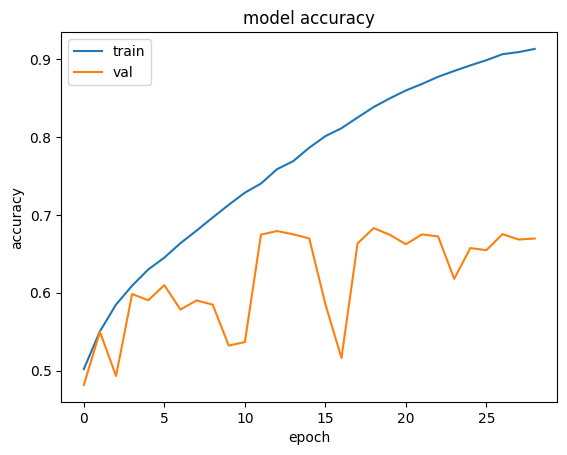

In [36]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

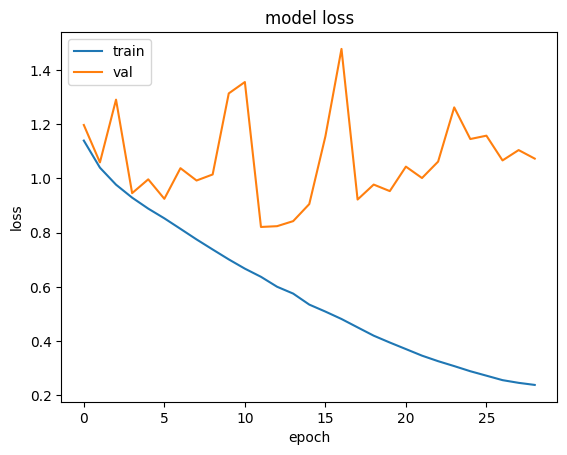

In [37]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [38]:
# model.save('./model_5_class_no_rotate')

In [39]:
test_loss, test_acc = model.evaluate(x_val, y_val)
print(f"test_loss={test_loss}, test_acc={test_acc}")

670/670 [==============================] - 4s 6ms/step - loss: 0.9776 - accuracy: 0.6830
test_loss=0.9775519967079163, test_acc=0.6830065250396729
